# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Darmanis GBM resolves into one continuous manifold with **no Gast-vs-pSom arm divergence** (tested
below with a principal *tree*). We fit a **principal curve** (scFates/ElPiGraph), root it at the
developmental origin (Gast/pSom-high, Crest-low), and read pseudotime.

**Representation for the fit (derived, not inherited).** The trajectory is fit on the
Harmony-integrated PCA representation (`X_pca_harmony`), **not** on the 2-D UMAP. This malignant
cloud is a shallow 2-D triangle (UMAP major/minor variance ratio ≈ 1.5) whose three module poles —
Gast, pSom, Crest — sit at its corners. The UMAP's dominant elongation is the Gast↔pSom edge, so a
curve fit *on the UMAP* follows that edge and terminates at the pSom corner, never reaching the
Crest pole — it would order the Gast→pSom internal gradient rather than the Gast/pSom→Crest
developmental axis the modules define (03_eval fork 4: do not read the trajectory off the embedding
being displayed). Fitting on the integrated PCA representation recovers the developmental axis whose
terminus is the neural-crest pole (Crest-high decile mean pseudotime ≈ 0.98). Modules are scored
here and **graph-smoothed** for geography/correlation reads; the deliverable UMAPs in 03 show the
**raw** scores, and `manifold.pdf` displays pseudotime on the house linear layout.

In [ ]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
import warnings; warnings.filterwarnings('ignore')
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
import logging; logging.getLogger('harmonypy').setLevel(logging.WARNING)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
Cells keep their integrated embedding from 01. Score Gast/pSom/Crest with the union control pool
(`score_genes`), then graph-smooth (3× kNN-connectivity averaging) for geography reads.

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
from numpy.linalg import svd; u,s,vt = svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=list(g), score_name=lab, ctrl_as_ref=False,
                      gene_pool=list(g_ref), random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('module means (raw):', adata.obs[['Gast','pSom','Crest']].mean().round(3).to_dict())

whole malignant manifold: 1091 cells
UMAP aspect ratio (major/minor std): 1.47
Gast: 71/81 genes present
pSom: 86/98 genes present
Crest: 100/104 genes present
module means (raw): {'Gast': 0.01, 'pSom': 0.099, 'Crest': 0.041}


### Topology test — tree vs curve (honest branching check)
Fit a principal **tree** and read the module identity at each tip. A genuine bifurcation would show
one Gast-leaning tip opposing a pSom-leaning tip. Here every tip is pSom-positive / Gast-low with no
opposing arm — the PPT "branch nodes" are artifacts of covering a 2-D cloud, not a real Y. Combined
with the spatial correlations (Gast/pSom **co-vary**; both oppose Crest), this is the **non-branching**
case: fit a curve, not a tree.

In [ ]:
print('smoothed spatial correlations (whole manifold):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a], adata.obs[b])[0,1]:+.2f}')
tree = adata.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(tree, method='ppt', Nodes=100, ppt_lambda=2000, ppt_sigma=0.5,
                use_rep='X_pca_harmony', seed=SEED, plot=False)
B = np.asarray(tree.uns['graph']['B']); deg = (B>0).sum(0)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
R = np.asarray(tree.obsm['X_R']); hard = R.argmax(1)
print(f'PPT tree: {int((deg==1).sum())} tips, {int((deg>=3).sum())} branch nodes — tip module identities:')
for tp in np.where(deg==1)[0]:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    print(f'  tip {tp} (n={m.sum()}): Gast={tree.obs.Gast_sm[m].mean():+.3f} '
          f'pSom={tree.obs.pSom_sm[m].mean():+.3f} Crest={tree.obs.Crest_sm[m].mean():+.3f}')
print('-> no Gast-leaning tip opposes a pSom-leaning tip; Gast/pSom co-vary -> NON-BRANCHING (fit a curve).')

smoothed spatial correlations (whole manifold):
  Gast_sm vs pSom_sm: r = +0.72
  Crest_sm vs Gast_sm: r = -0.92
  Crest_sm vs pSom_sm: r = -0.59
PPT tree: 3 tips, 1 branch nodes — tip module identities:
  tip 27 (n=160): Gast=-0.023 pSom=+0.081 Crest=+0.085
  tip 68 (n=180): Gast=+0.040 pSom=+0.124 Crest=+0.022
  tip 83 (n=213): Gast=+0.049 pSom=+0.092 Crest=-0.012
-> no Gast-leaning tip opposes a pSom-leaning tip; Gast/pSom co-vary -> NON-BRANCHING (fit a curve).


### Fit the principal curve (ElPiGraph) on the integrated PCA representation
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone, fit on `X_pca_harmony` (see the
representation note above — fitting on the 2-D UMAP would truncate the axis at the pSom corner). The
fold self-approach ratio (min Euclidean distance between graph-distant nodes / median edge length)
must exceed 1, and the graph must have exactly 2 tips and 0 forks.

In [ ]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    return dmin/med, int(((B>0).sum(0)==1).sum()), int(((B>0).sum(0)>=3).sum())
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_pca_harmony', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.97 (>1 = fold-free)


### Derive the root (developmental order — Crest is late)
The root is the curve tip where Gast+pSom is highest and Crest lowest (the gastrulation/somitogenesis
origin). Neural crest is a **late** readout, so it must not seed the root (03_eval fork 3).

In [ ]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs.Gast_sm[m].mean(), adata.obs.pSom_sm[m].mean(), adata.obs.Crest_sm[m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed scores):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f} (p={p:.1e})')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')

tip 0: Gast=+0.0474 pSom=+0.0918 Crest=-0.0107
tip 2: Gast=-0.0182 pSom=+0.0857 Crest=+0.0791
derived root = tip 0 (Gast/pSom-high, Crest-low developmental origin)
gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho = -0.608 (p=2.8e-111)
  pSom_sm: rho = -0.145 (p=1.6e-06)
  Crest_sm: rho = +0.807 (p=9.3e-252)
Crest-high decile mean pseudotime = 0.98 (terminal if ~1)


### Reorient to house style (pseudotime left → right)
Orient using only the raw UMAP coordinates so the layout is independent of the fitted curve; flip x
if needed so low pseudotime sits on the left. No re-embedding (03_eval fork 4).

In [ ]:
xy = adata.obsm['X_umap'].copy(); t = adata.obs['t'].values
xyr = np.column_stack([xy[:,0], xy[:,1]])
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:
    xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
adata.obsm['X_umap_lin'] = xyr
print(f'orientation: corr(x_lin, pseudotime) = {r:+.2f} (low pt -> left)')

orientation: corr(x_lin, pseudotime) = +0.83 (low pt -> left)


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


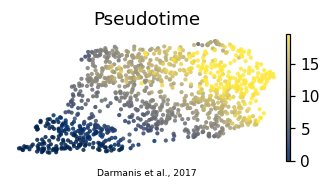

In [ ]:
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.85, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Darmanis et al., 2017', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')